In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, pandas as pd
from datetime import datetime
from zoneinfo import ZoneInfo

BASE = '/content/drive/MyDrive/vitaldb-aki'
for sub in ['data', 'outputs', 'figures', 'models']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)

def load_table(name):
    """드라이브에 있으면 거기서 읽고, 없으면 VitalDB에서 받아서 드라이브에 저장"""
    path = f'{BASE}/data/{name}.csv'
    if not os.path.exists(path):
        pd.read_csv(f'https://api.vitaldb.net/{name}').to_csv(path, index=False)
    return pd.read_csv(path)

def save_df(df, name):
    """결과 표를 한국 시간 붙여서 드라이브에 저장 (덮어쓰기 방지)"""
    ts = datetime.now(ZoneInfo('Asia/Seoul')).strftime('%m%d_%H%M')
    path = f"{BASE}/outputs/{name}_{ts}.csv"
    df.to_csv(path, index=False)
    print('저장됨:', path)

print('드라이브 마운트됨:', os.path.ismount('/content/drive'))

RUN_HEAVY = False   # True면 오래 걸리는 동맥 라인 vs 커프 비교 실행

Mounted at /content/drive
드라이브 마운트됨: True


In [2]:
!pip install vitaldb
import vitaldb
import pandas as pd

cases = pd.read_csv('https://api.vitaldb.net/cases')  # 환자/수술 정보
labs  = pd.read_csv('https://api.vitaldb.net/labs')   # 검사 수치
trks  = pd.read_csv('https://api.vitaldb.net/trks')   # 케이스별 기록된 신호 목록

print(cases.shape, labs.shape, trks.shape)
cases.head()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 11.0 MB/s eta 0:00:00
(6388, 74) (928448, 4) (486449, 3)


,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1,5955,0,11542,-552,10848.0,1668,10368,-236220,627780,...,0,120,0.0,100,70,0,10,0,0,0
1,2,2487,0,15741,-1039,14921.0,1721,14621,-221160,1506840,...,0,150,0.0,0,100,0,20,0,0,0
2,3,2861,0,4394,-590,4210.0,1090,3010,-218640,40560,...,0,0,0.0,0,50,0,0,0,0,0
3,4,1903,0,20990,-778,20222.0,2522,17822,-201120,576480,...,0,80,0.0,100,100,0,50,0,0,0
4,5,4416,0,21531,-1009,22391.0,2591,20291,-67560,3734040,...,0,0,0.0,0,160,0,10,900,0,2100


In [3]:
cases = load_table('cases')
labs  = load_table('labs')
trks  = load_table('trks')

In [4]:
cr = labs[labs['name'] == 'cr']
cr = cr.merge(cases[['caseid', 'opend']], on='caseid')
week = 7 * 24 * 3600
postop = cr[(cr['dt'] > cr['opend']) & (cr['dt'] <= cr['opend'] + week)]
postop_max = postop.groupby('caseid')['result'].max().rename('postop_cr_max')

df = cases.merge(postop_max, on='caseid')
df = df[df['preop_cr'].notna()]
df['aki'] = (df['postop_cr_max'] >= 1.5 * df['preop_cr']).astype(int)

print('분석 대상 케이스 수:', len(df))
print('AKI 비율:', round(df['aki'].mean(), 3))
#save_df(df, 'aki_dataset')

분석 대상 케이스 수: 3989
AKI 비율: 0.053


"기록이 없는 환자는 뺀다"고 했잖아. 그런데 수술 후에 크레아티닌을 아예 안 잰 환자는 어떤 사람들일까? 아마 비교적 가벼운 수술을 받은, 상태가 괜찮았던 환자들일 가능성이 높아. 그러면 우리 데이터는 원래 환자 전체보다 좀 더 "아픈 쪽"으로 치우쳐 있다는 뜻이 되고, 이걸 선택 편향(selection bias)이라고 해. 지금 당장 고칠 건 아니고, 나중에 README에 한계점으로 적어두면 좋은 포인트야.

AUROC는 "AKI 환자와 아닌 환자를 한 명씩 무작위로 뽑았을 때, 모델이 AKI 환자에게 더 높은 위험 점수를 줄 확률"

In [5]:
preop_cols = ['age', 'sex', 'bmi', 'asa', 'emop'] + \
             [c for c in df.columns if c.startswith('preop_')]

missing = df[preop_cols].isna().mean().round(3).sort_values()
print(missing)

age            0.000
sex            0.000
bmi            0.000
asa            0.000
emop           0.000
preop_htn      0.000
preop_dm       0.000
preop_ecg      0.000
preop_pft      0.000
preop_cr       0.000
preop_bun      0.001
preop_ast      0.002
preop_alb      0.002
preop_alt      0.003
preop_hb       0.004
preop_plt      0.006
preop_gluc     0.007
preop_pt       0.014
preop_aptt     0.016
preop_k        0.057
preop_na       0.058
preop_ph       0.905
preop_paco2    0.907
preop_pao2     0.907
preop_be       0.908
preop_hco3     0.908
preop_sao2     0.908
dtype: float64


In [6]:
for col in ['sex', 'asa', 'emop', 'preop_htn', 'preop_dm', 'preop_ecg', 'preop_pft']:
    print(col, df[col].value_counts().to_dict())
    print()

sex {'M': 2312, 'F': 1677}

asa {2.0: 2506, 1.0: 896, 3.0: 550, 4.0: 32, 6.0: 5}

emop {0: 3484, 1: 505}

preop_htn {0: 2635, 1: 1354}

preop_dm {0: 3501, 1: 488}

preop_ecg {'Normal Sinus Rhythm': 3924, 'Right bundle branch block': 9, 'Incomplete right bundle branch block': 8, 'Atrial fibrillation': 7, 'Premature ventricular complexes': 7, 'Premature atrial complexes': 6, '1st degree A-V block': 6, 'Left anterior fascicular block': 3, 'Atrial fibrillation with slow ventricular response': 2, 'Premature supraventricular complexes': 2, 'Premature supraventricular and ventricular complexes, Right bundle branch block': 1, 'Incomplete right bundle branch block, Left anterior fascicular block': 1, 'Atrial fibrillation, Right bundle branch block': 1, 'Left posterior fascicular block': 1, 'Atrial fibrillation with rapid ventricular response': 1, 'Atrial fibrillation with premature ventricular, Incomplete left bundle block': 1, 'Left anterior hemiblock': 1, '1st degree A-V block with Premature 

ASA 6이 5건 있잖아. ASA 6은 "장기 기증을 위해 장기를 적출하는 뇌사자"야. 이 수술은 환자를 살리기 위한 수술이 아니고, 수술 후 경과라는 개념 자체가 없어서 AKI 예측 대상이 될 수 없어. 그래서 이 5건은 분석에서 빼야 해. 이렇게 "이 데이터가 내 연구 질문에 해당하는 환자인가"를 따져서 대상을 고르는 걸 **포함/제외 기준(inclusion/exclusion criteria)**이라고 하고, 논문 Methods에 반드시 들어가는 부분이야. README에도 "ASA 6(뇌사 장기기증자) 제외"라고 적어두자.

In [7]:
cases['opdur'] = (cases['opend'] - cases['opstart']) / 60   # 초 → 분
included = cases['caseid'].isin(df['caseid'])
cases.groupby(included)[['age', 'asa', 'emop', 'opdur', 'icu_days']].mean().round(2)

,age,asa,emop,opdur,icu_days
caseid,,,,,
False,53.91,1.70,0.12,86.30,0.41
True,59.34,1.93,0.13,165.87,0.64


수술 후 크레아티닌 측정 여부로 분석 대상을 선정한 결과, 포함군(n=3989)은 제외군(n=2399)에 비해 고령이고(59.3 vs 53.9세), ASA 등급이 높으며(1.93 vs 1.70), 수술 시간이 길고(166 vs 86분), 수술 후 ICU 재원일수가 길었다(0.64 vs 0.41일). 응급 수술 비율은 비슷했다(13% vs 12%). 이는 분석 대상이 상대적으로 큰 수술을 받은, AKI 위험이 높은 환자 쪽으로 치우쳐 있음을 시사하며, 따라서 본 연구의 AKI 발생률(5.3%)은 전체 수술 환자에서의 발생률보다 높게 추정되었을 수 있다.

In [8]:
# 1) 제외 기준: ASA 6 (뇌사 장기기증자)
df = df[df['asa'] != 6].copy()

# 2) 글자 변수를 0/1로 변환
df['sex_m']        = (df['sex'] == 'M').astype(int)
df['ecg_abnormal'] = (df['preop_ecg'] != 'Normal Sinus Rhythm').astype(int)
df['pft_abnormal'] = (df['preop_pft'] != 'Normal').astype(int)

print('케이스 수:', len(df), '/ AKI 비율:', round(df['aki'].mean(), 3))

# 3) 그룹별 AKI 발생률 비교
for col in ['sex_m', 'emop', 'preop_htn', 'preop_dm', 'ecg_abnormal', 'pft_abnormal', 'asa']:
    print(col, df.groupby(col)['aki'].mean().round(3).to_dict())

# 4) 아까 빠진 수술 정보 변수 확인
for col in ['department', 'optype', 'approach']:
    print(col, df[col].value_counts().to_dict())

케이스 수: 3984 / AKI 비율: 0.053
sex_m {0: 0.049, 1: 0.056}
emop {0: 0.048, 1: 0.089}
preop_htn {0: 0.057, 1: 0.046}
preop_dm {0: 0.054, 1: 0.043}
ecg_abnormal {0: 0.052, 1: 0.108}
pft_abnormal {0: 0.052, 1: 0.056}
asa {1.0: 0.065, 2.0: 0.028, 3.0: 0.133, 4.0: 0.344}
department {'General surgery': 2958, 'Thoracic surgery': 883, 'Urology': 83, 'Gynecology': 60}
optype {'Colorectal': 969, 'Stomach': 618, 'Others': 503, 'Major resection': 431, 'Minor resection': 399, 'Biliary/Pancreas': 351, 'Transplantation': 348, 'Hepatic': 233, 'Vascular': 108, 'Breast': 12, 'Thyroid': 12}
approach {'Open': 1925, 'Videoscopic': 1898, 'Robotic': 161}


3번이 이번 셀의 핵심인데, groupby(col)['aki'].mean()은 "이 변수가 0인 그룹과 1인 그룹에서 각각 AKI가 몇 %나 생겼나"를 보여줘. 예를 들어 응급 수술 그룹의 AKI 비율이 비응급보다 확연히 높다면, 모델을 돌리기 전에 이미 "이 변수는 중요하겠구나"를 눈으로 확인하는 거야.

첫째, 고혈압과 당뇨 환자의 AKI 비율이 오히려 더 낮아. 둘 다 교과서적인 AKI 위험 인자인데 거꾸로 나왔어. 둘째, ASA 1(건강한 환자)이 6.5%로 ASA 2(2.8%)보다 두 배 이상 높아. 가장 건강한 환자들이 AKI가 더 많다는 건 말이 안 되지.

이렇게 상식과 반대되는 결과가 나오면 "데이터에 뭔가 숨어 있다"는 신호야. 내가 의심하는 건 optype의 Transplantation(이식) 348건이야. 이식 수술에는 두 종류의 환자가 섞여 있어.

하나는 생체 신장 기증자야. 건강한 사람(ASA 1)이 신장 하나를 떼어주면, 남은 신장 하나로 버텨야 하니까 크레아티닌이 원래 값의 1.5배 가까이 오르는 게 정상이야. 신장이 손상된 게 아니라 신장 개수가 줄어든 건데, 우리 정의로는 AKI로 찍혀버려. 이게 ASA 1의 AKI 비율을 끌어올렸을 수 있어.

다른 하나는 신장 이식 수혜자야. 이분들은 말기 신부전이라 수술 전 크레아티닌이 아주 높고, 새 신장을 받으면 크레아티닌이 오히려 뚝 떨어져. 그러니 우리 정의로는 거의 AKI가 0이 나오지. 그런데 말기 신부전 환자들은 대부분 고혈압, 당뇨를 갖고 있어. 그래서 이분들이 고혈압·당뇨 그룹의 AKI 비율을 끌어내렸을 수 있어.

이 두 경우 모두 "AKI"라는 개념이 원래 의도와 다르게 작동하는 환자들이야. 이게 맞다면 아까 ASA 6을 뺀 것처럼 제외 기준에 넣어야 해. 그냥 모델을 돌렸다면 모델은 "신장 기증 = AKI"를 열심히 배웠을 거고, 숫자는 그럴듯해도 임상적으로는 쓸모없는 모델이 됐을 거야. 모델 돌리기 전에 EDA를 하는 이유가 바로 이거야.

In [9]:
# 1) 수술 종류별 AKI 비율과 환자 수
print(df.groupby('optype')['aki'].agg(['mean', 'count']).round(3).sort_values('mean', ascending=False))

# 2) ASA 1인데 AKI가 생긴 환자들은 무슨 수술을 받았나
print(df[(df['asa'] == 1) & (df['aki'] == 1)]['opname'].value_counts().head(10))

# 3) 이식 수술 그룹 안에는 어떤 수술들이 있나
print(df[df['optype'] == 'Transplantation']['opname'].value_counts().head(15))

                   mean  count
optype                        
Transplantation   0.302    348
Vascular          0.093    108
Thyroid           0.083     12
Others            0.076    503
Biliary/Pancreas  0.043    351
Hepatic           0.034    233
Major resection   0.021    431
Colorectal        0.018    969
Minor resection   0.010    399
Stomach           0.006    618
Breast            0.000     12
opname
Donor nephrectomy                  50
Donor hepatectomy                   2
Cholecystectomy                     1
Hemicolectomy                       1
Anterior resection                  1
Small bowel segmental resection     1
Hemihepatectomy                     1
Radical cystectomy                  1
Name: count, dtype: int64
opname
Kidney transplantation                          107
Liver transplantation                            89
Donor nephrectomy                                79
Donor hepatectomy                                65
Lung transplantation                         

In [10]:
kidney_mask = df['opname'].str.contains('nephrectomy|kidney transplantation',
                                        case=False, na=False)
print(df[kidney_mask]['opname'].value_counts())
print('제외 대상:', kidney_mask.sum(), '명 / 이 그룹 AKI 비율:', round(df.loc[kidney_mask, 'aki'].mean(), 3))

opname
Kidney transplantation                          107
Donor nephrectomy                                79
Nephrectomy                                      13
Simultaneous pancreas-kidney transplantation      2
Name: count, dtype: int64
제외 대상: 201 명 / 이 그룹 AKI 비율: 0.353


str.contains는 수술명에 해당 단어가 들어 있는지 찾아주고, |는 "또는"이야. case=False는 대소문자를 무시하라는 뜻이라 "Kidney"와 "kidney"를 둘 다 잡고, "Simultaneous pancreas-kidney transplantation"도 "kidney transplantation"이 포함돼서 같이 걸려. na=False는 수술명이 비어 있는 행은 해당 없음으로 처리하라는 거야.

In [11]:
df = df[~kidney_mask].copy()
print('케이스 수:', len(df), '/ AKI 비율:', round(df['aki'].mean(), 3))

for col in ['asa', 'preop_htn', 'preop_dm']:
    print(col, df.groupby(col)['aki'].mean().round(3).to_dict())

케이스 수: 3783 / AKI 비율: 0.037
asa {1.0: 0.01, 2.0: 0.025, 3.0: 0.125, 4.0: 0.355}
preop_htn {0: 0.036, 1: 0.039}
preop_dm {0: 0.037, 1: 0.04}


In [12]:
# 1) 수술 후 크레아티닌 재계산: 생리적으로 불가능한 값 제거
cr_all = labs[labs['name'] == 'cr'].merge(cases[['caseid', 'opend', 'preop_cr']], on='caseid')
post = cr_all[(cr_all['dt'] > cr_all['opend']) & (cr_all['dt'] <= cr_all['opend'] + week)]

implausible = (post['result'] > 15) & (post['preop_cr'] < 4)
print('제거할 기록:', implausible.sum(), '건 /', post.loc[implausible, 'caseid'].nunique(), '명')
new_max = post[~implausible].groupby('caseid')['result'].max()

old_aki = df['aki'].copy()
df['postop_cr_max'] = df['caseid'].map(new_max)
df = df[df['postop_cr_max'].notna()].copy()
df['aki'] = (df['postop_cr_max'] >= 1.5 * df['preop_cr']).astype(int)
print('AKI 판정이 바뀐 환자:', (old_aki.loc[df.index] != df['aki']).sum(), '명')

# 2) 제외 기준: 말기 신장병 (수술 전 Cr ≥ 4 또는 동정맥루 수술)
esrd = (df['preop_cr'] >= 4) | df['opname'].str.contains('arteriovenous fistula', case=False, na=False)
print('말기 신장병 추정 제외:', esrd.sum(), '명 / 그중 AKI', df.loc[esrd, 'aki'].sum(), '명')
df = df[~esrd].copy()

print('최종:', len(df), '명 / AKI', df['aki'].sum(), '명', f'({df["aki"].mean():.3f})')
#save_df(df, 'aki_dataset_v3')

제거할 기록: 3 건 / 3 명
AKI 판정이 바뀐 환자: 1 명
말기 신장병 추정 제외: 66 명 / 그중 AKI 7 명
최종: 3717 명 / AKI 132 명 (0.036)


In [13]:
# 1) 수술 후 48시간 이내 최고 크레아티닌 (불가능한 값은 v3에서처럼 제외)
h48 = 48 * 3600
post_clean = post[~implausible]
max48 = (post_clean[post_clean['dt'] <= post_clean['opend'] + h48]
         .groupby('caseid')['result'].max())
df['postop_cr_max48'] = df['caseid'].map(max48)

# 2) KDIGO 정의: 7일 내 1.5배 이상 OR 48시간 내 0.3 이상 상승
df['aki_kdigo'] = ((df['postop_cr_max'] >= 1.5 * df['preop_cr']) |
                   ((df['postop_cr_max48'] - df['preop_cr']) >= 0.3)).astype(int)

# 3) 비교
print('기존 정의 AKI :', df['aki'].sum(), f"({df['aki'].mean():.3f})")
print('KDIGO 정의 AKI:', df['aki_kdigo'].sum(), f"({df['aki_kdigo'].mean():.3f})")

new = (df['aki_kdigo'] == 1) & (df['aki'] == 0)
print('\n새로 AKI가 된 환자:', new.sum(), '명')
print(df.loc[new, 'preop_cr'].describe().round(2))
print(df.loc[new, 'opname'].value_counts().head(8))

기존 정의 AKI : 132 (0.036)
KDIGO 정의 AKI: 175 (0.047)

새로 AKI가 된 환자: 43 명
count    43.00
mean      1.29
std       0.84
min       0.63
25%       0.80
50%       1.06
75%       1.30
max       3.93
Name: preop_cr, dtype: float64
opname
Exploratory laparotomy                        5
Liver transplantation                         4
Bleeding control                              4
Anterior resection                            3
Lung lobectomy                                3
Lung wedge resection                          2
Pylorus preserving pancreaticoduodenectomy    2
Esophagectomy                                 2
Name: count, dtype: int64


고혈압, 당뇨환자의 aki비율이 정상그룹의 aki비율과 큰 차이가 없는 이유 : 단변량 분석, thn,dm이 kideny를 해치는 효과는 이미 preop_cr과 같은 변수에 반영되어 있음, 모집단의 수가 적음

In [14]:
#save_df(df, 'aki_dataset_v2')

여기까지가 대상자 선정, 변수변환, EDA.
최종분석 대상 : VitalDB 6388건 중 **3783명, AKI 3.7%**이고, 제외 기준은 "수술 후 크레아티닌 없음 / 수술 전 크레아티닌 없음 / ASA 6 / 신장 절제·신장 이식

변수변환 : 원래 변수
sex	: M / F	-> sex_m	남자면 1, 여자면 0
preop_ecg	: 25가지 판독문	 -> ecg_abnormal	"Normal Sinus Rhythm"이면 0, 나머지는 전부 1

preop_pft	: 9가지 결과 ->	pft_abnormal	"Normal"이면 0, 나머지는 전부 1

*원-핫 인코딩(One-Hot Encoding): 순서가 없는 범주형 데이터를 컴퓨터가 이해할 수 있도록 0과 1로 이루어진 숫자 벡터로 변환하는 방식*

In [15]:
print('수술 건수:', len(df), '/ 환자 수:', df['subjectid'].nunique())

수술 건수: 3717 / 환자 수: 3553


In [16]:
num_cols = ['age', 'bmi', 'asa', 'preop_cr', 'preop_bun', 'preop_hb', 'preop_plt',
            'preop_pt', 'preop_aptt', 'preop_na', 'preop_k', 'preop_gluc',
            'preop_alb', 'preop_ast', 'preop_alt']
bin_cols = ['sex_m', 'emop', 'preop_htn', 'preop_dm', 'ecg_abnormal', 'pft_abnormal']
cat_cols = ['department', 'optype', 'approach']

X = pd.concat([df[num_cols + bin_cols], #optype을 Colorectal=1, Stomach=2, Hepatic=3처럼 숫자로 바꾸면 모델이 "Hepatic이 Colorectal보다 3배 크다"는 식으로 엉뚱한 순서를 배움
               pd.get_dummies(df[cat_cols], dtype=int)], axis=1) #get_dummies로 원-핫 인코딩(one-hot encoding)
y = df['aki']
groups = df['subjectid']
print('X 크기:', X.shape)
print(X.columns.tolist())

X 크기: (3717, 39)
['age', 'bmi', 'asa', 'preop_cr', 'preop_bun', 'preop_hb', 'preop_plt', 'preop_pt', 'preop_aptt', 'preop_na', 'preop_k', 'preop_gluc', 'preop_alb', 'preop_ast', 'preop_alt', 'sex_m', 'emop', 'preop_htn', 'preop_dm', 'ecg_abnormal', 'pft_abnormal', 'department_General surgery', 'department_Gynecology', 'department_Thoracic surgery', 'department_Urology', 'optype_Biliary/Pancreas', 'optype_Breast', 'optype_Colorectal', 'optype_Hepatic', 'optype_Major resection', 'optype_Minor resection', 'optype_Others', 'optype_Stomach', 'optype_Thyroid', 'optype_Transplantation', 'optype_Vascular', 'approach_Open', 'approach_Robotic', 'approach_Videoscopic']


In [17]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42) #Stratified(층화):train과 test의 AKI 비율이 비슷하게 유지
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print('train:', len(X_train), '명 / AKI', y_train.sum(), '명', round(y_train.mean(), 3))
print('test :', len(X_test), '명 / AKI', y_test.sum(), '명', round(y_test.mean(), 3))
print('train·test 양쪽에 다 있는 환자 수:',
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

train: 2976 명 / AKI 109 명 0.037
test : 741 명 / AKI 23 명 0.031
train·test 양쪽에 다 있는 환자 수: 0


21명으로 성능을 재면, 몇 명을 더 맞히고 못 맞히느냐에 따라 숫자가 크게 출렁여. 그래서 나중에 성능을 보고할 땐 test 결과 하나만 믿지 않고, 교차검증이나 신뢰구간으로 "얼마나 믿을 만한 숫자인지"를 같이 보여줄 거야. 일단은 진행하고, 결과를 볼 때 이 점만 기억해두자.

In [18]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test  = X_test.fillna(medians)

print('남은 결측 - train:', X_train.isna().sum().sum(), '/ test:', X_test.isna().sum().sum())

남은 결측 - train: 0 / test: 0


로지스틱 회귀는 각 변수에 가중치를 곱해서 더한 다음, 그걸 0~1 사이의 확률로 바꿔주는 가장 기본적인 분류 모델이야. 단순해서 성능이 최고는 아니지만, 이게 **기준선(baseline)**이 돼서 나중에 XGBoost가 "얼마나 더 나아졌는지"를 잴 수 있어.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# 1) 변수 크기 맞추기
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
         #표준화(standardization) : age:20~80/ 크레아닌:~1 -> 큰숫자를 중요하게 생각할 수 있음 그래서 모든 변수에 대하여 평균0,표준편차1로 통일

# 2) 학습
lr = LogisticRegression(max_iter=1000) #max_iter=1000: 최적의 가중치를 찾을 때까지 최대 1000번 반복 가능

lr.fit(X_train_s, y_train)

# 3) test에서 AKI 확률 예측 후 평가
p_test = lr.predict_proba(X_test_s)[:, 1]
print('AUROC:', round(roc_auc_score(y_test, p_test), 3))
print('AUPRC:', round(average_precision_score(y_test, p_test), 3),
      '(기준선', round(y_test.mean(), 3), ')')

AUROC: 0.853
AUPRC: 0.423 (기준선 0.031 )


In [20]:
#모델이 각 변수에 준 가중치를 직접확인
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()

print('▲ AKI 위험을 높이는 쪽 (상위 10개)')
print(coef.round(2).tail(10)[::-1])
print()
print('▼ AKI 위험을 낮추는 쪽 (상위 10개)')
print(coef.round(2).head(10))

▲ AKI 위험을 높이는 쪽 (상위 10개)
preop_alt                 0.47
sex_m                     0.26
optype_Transplantation    0.26
preop_htn                 0.21
asa                       0.19
approach_Open             0.18
optype_Minor resection    0.17
optype_Major resection    0.14
department_Urology        0.13
optype_Hepatic            0.13
dtype: float64

▼ AKI 위험을 낮추는 쪽 (상위 10개)
preop_alb              -0.41
preop_hb               -0.38
optype_Stomach         -0.33
optype_Colorectal      -0.29
preop_ast              -0.26
approach_Videoscopic   -0.22
emop                   -0.21
optype_Breast          -0.16
preop_plt              -0.16
pft_abnormal           -0.15
dtype: float64


In [21]:
#헤모글로빈(preop_hb), 알부민(preop_alb)등이 음수인데 이건 값이 낮을수록 위험 하다는 뜻
#고혈압(preop_htn)도 높게 나옴.단변량비교에선 정상군과 비정상군이 큰 차이 없었는데 반함.
#이상한점 : 수술전 크레아닌수치가 없음(신기능을 직접적으로 보여주는 변수), preop_bun이 음수임 bun이 높으면 신기능이 나쁘다는 뜻인데 음수로 나왔으므로 높으면 aki가능성이 줄어든다고 해석됨 지금은.
#이상한점 : 나이도 음수로 나왔고(통상적으로 나이가 많으면 더 위험해야함), ALT도 위험을 높히는 쪽에 있음

In [22]:
#의심되는 원인 : 간 질환 환자들 - 이식수술에서 신장이식을 제외하였기 때문에 대부분의 이식환자는 간이식 수혜자들로 구성됨
#간경화 말기 : 간이 효소를 만들지 못하기 때문에 bun,크레아닌이 낮고 간손상으로 인하여 alt가 높음

In [23]:
#모델이 학습한 큰 덩어리 중 하나가 "간 질환 환자처럼 생긴 검사 패턴 = AKI 위험"일 가능성이 높음

크레아티닌이 상위권에 없는 것도 연결돼. 우리 정의는 "수술 전 대비 1.5배"라서, 기저 크레아티닌이 0.5처럼 낮은 환자는 0.75만 돼도 AKI로 찍혀. 같은 1.5배라도 낮은 기저치에서는 작은 변화로 기준을 넘기 쉬운 거지. 그래서 크레아티닌의 효과가 "높으면 위험"과 "낮으면 기준 넘기 쉬움"으로 섞여서 상쇄됐을 수 있어. 여기에 크레아티닌과 BUN은 서로 비슷한 정보를 담고 있어서 가중치를 나눠 가지는 효과(다중공선성)도 겹쳤을 거고.

In [24]:
# 1) 크레아티닌 계수와, 크레아티닌·BUN의 상관관계
print('preop_cr 계수:', round(coef['preop_cr'], 2))
print(df[['preop_cr', 'preop_bun']].corr().round(2))
print()

# 2) AKI 환자가 가장 많이 나온 수술명
print(df.groupby('opname')['aki'].agg(['sum', 'count', 'mean']).round(3)
        .sort_values('sum', ascending=False).head(10))

preop_cr 계수: -0.14
           preop_cr  preop_bun
preop_cr       1.00       0.63
preop_bun      0.63       1.00

                                            sum  count   mean
opname                                                       
Liver transplantation                        33     88  0.375
Exploratory laparotomy                       21    174  0.121
Hemihepatectomy                               6     79  0.076
Pylorus preserving pancreaticoduodenectomy    6    115  0.052
Excision                                      5    112  0.045
Bleeding control                              5     23  0.217
Hemicolectomy                                 4    168  0.024
Cholecystectomy                               4     63  0.063
Radical cystectomy                            4      6  0.667
Anterior resection                            3    220  0.014


In [25]:
#save_df(df, 'aki_dataset_v2')
#save_df(coef.rename('coef').reset_index().rename(columns={'index': 'variable'}), 'lr_coef_v3')

In [26]:
from sklearn.pipeline import make_pipeline #5묶음 의 data set으로 교차검증 시행
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

pipe = make_pipeline(SimpleImputer(strategy='median'),                       #파이프라인(pipeline) : 결측치 대체, 표준화, 모델을 하나로 묶어둔 것
                     StandardScaler(),
                     LogisticRegression(max_iter=1000))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(pipe, X, y, groups=groups, cv=cv,
                     scoring=['roc_auc', 'average_precision'])

for name, key in [('AUROC', 'test_roc_auc'), ('AUPRC', 'test_average_precision')]:
    print(name, res[key].round(3), '→ 평균', res[key].mean().round(3), '±', res[key].std().round(3))

AUROC [0.853 0.856 0.783 0.713 0.837] → 평균 0.808 ± 0.054
AUPRC [0.423 0.373 0.234 0.191 0.467] → 평균 0.338 ± 0.108


In [27]:
#AUPRC 기준으로 성능이 좋았던 1,3번째에 간이식 환자수가 많고 5번째에 간이식 환자 수가 적다면 해당모델이 간이식을 강하게 학습했다는 뜻이됨.
#추후 학습에서 간이식 여부를 배제시킬지 고민해 볼 수 있음

In [28]:
is_liver = (df['opname'] == 'Liver transplantation').values

for i, (tr, te) in enumerate(cv.split(X, y, groups), 1):
    aki_te = y.iloc[te].values == 1
    print(f'회차 {i}: AKI {aki_te.sum()}명 / 그중 간이식 {(aki_te & is_liver[te]).sum()}명'
          f' / AKI 비율 {aki_te.mean():.3f}')

회차 1: AKI 23명 / 그중 간이식 7명 / AKI 비율 0.031
회차 2: AKI 16명 / 그중 간이식 4명 / AKI 비율 0.021
회차 3: AKI 27명 / 그중 간이식 6명 / AKI 비율 0.036
회차 4: AKI 34명 / 그중 간이식 6명 / AKI 비율 0.046
회차 5: AKI 32명 / 그중 간이식 10명 / AKI 비율 0.043


In [29]:
import numpy as np
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(pipe, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]  #OOF : out-of-fold
y_arr = y.values

def report(mask, name):
    yt, pt = y_arr[mask], oof[mask]
    print(f'{name}: {mask.sum()}명, AKI {yt.sum()}명 ({yt.mean():.3f})'
          f' / AUROC {roc_auc_score(yt, pt):.3f} / AUPRC {average_precision_score(yt, pt):.3f}')

report(np.ones(len(y_arr), dtype=bool), '전체      ')
report(~is_liver,                      '간이식 제외')
report(is_liver,                       '간이식만  ')

전체      : 3717명, AKI 132명 (0.036) / AUROC 0.792 / AUPRC 0.295
간이식 제외: 3629명, AKI 99명 (0.027) / AUROC 0.735 / AUPRC 0.175
간이식만  : 88명, AKI 33명 (0.375) / AUROC 0.695 / AUPRC 0.555


In [30]:
#전체의 AUROC가 부분보다 높다는 뜻은 모델이 그룹을 구분(간이식 수술과 그외 수술로)하는 능력과 그룹안에서 구분(간이식 환자중 누가 AKI가 생길지)하는 능력이 있다는 뜻
#전체를 볼 경우 첫번째 능력이 보태져 점수가 높았던것.
#간이식 환자들만 봤을떄는 두번째 능력으로만 판단해야하는데, 수술전 정보가 대부분 비슷비슷하기 때문에 "수술중"정보가 더 중요하게 됨

In [31]:
#AUPRC는 그룹마다 기준선이 달라서, 숫자 자체보다 기준선 대비 몇 배인지로 봐야함

In [32]:
results = pd.DataFrame({'caseid': df['caseid'].values, 'aki': y_arr,
                        'is_liver': is_liver, 'oof_lr': oof})
#save_df(results, 'oof_lr_v3')

In [33]:
from xgboost import XGBClassifier  #n_estimators=300은 나무를 300그루 쌓는다는 것, max_depth=3은 나무 하나가 질문을 최대 3단계까지만 던진다는 것(데이터가 작아서 나무가 너무 깊으면 train만 외워버리니까 얕게)

xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric='logloss', random_state=42)

#learning_rate=0.05는 나무 하나하나의 영향력을 작게 해서 조금씩 신중하게 배우게 하는 것, subsample과 colsample_bytree=0.8은 나무마다 환자와 변수의 80%만 무작위로 보게 해서 특정 데이터에 과하게 맞추는 걸 막는 거

res_xgb = cross_validate(xgb, X, y, groups=groups, cv=cv,
                         scoring=['roc_auc', 'average_precision'])

for name, key in [('AUROC', 'test_roc_auc'), ('AUPRC', 'test_average_precision')]:
    print(name, res_xgb[key].round(3), '→ 평균', res_xgb[key].mean().round(3),
          '±', res_xgb[key].std().round(3))

AUROC [0.86  0.86  0.742 0.715 0.856] → 평균 0.807 ± 0.064
AUPRC [0.499 0.295 0.244 0.144 0.451] → 평균 0.327 ± 0.132


In [34]:
oof_xgb = cross_val_predict(xgb, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]

def report(mask, name, pred):
    yt, pt = y_arr[mask], pred[mask]
    return f'{name}: AUROC {roc_auc_score(yt, pt):.3f} / AUPRC {average_precision_score(yt, pt):.3f}'

groups_to_check = [(np.ones(len(y_arr), dtype=bool), '전체      '),
                   (~is_liver,                      '간이식 제외'),
                   (is_liver,                       '간이식만  ')]

for mask, name in groups_to_check:
    print('로지스틱 |', report(mask, name, oof))
    print('XGBoost  |', report(mask, name, oof_xgb))
    print()

results['oof_xgb'] = oof_xgb
#save_df(results, 'oof_lr_xgb_v3')

로지스틱 | 전체      : AUROC 0.792 / AUPRC 0.295
XGBoost  | 전체      : AUROC 0.786 / AUPRC 0.281

로지스틱 | 간이식 제외: AUROC 0.735 / AUPRC 0.175
XGBoost  | 간이식 제외: AUROC 0.730 / AUPRC 0.172

로지스틱 | 간이식만  : AUROC 0.695 / AUPRC 0.555
XGBoost  | 간이식만  : AUROC 0.704 / AUPRC 0.577



In [35]:
for name, key in [('AUROC', 'test_roc_auc'), ('AUPRC', 'test_average_precision')]:
    print(name, res_xgb[key].round(3), '→ 평균', res_xgb[key].mean().round(3),
          '±', res_xgb[key].std().round(3))

AUROC [0.86  0.86  0.742 0.715 0.856] → 평균 0.807 ± 0.064
AUPRC [0.499 0.295 0.244 0.144 0.451] → 평균 0.327 ± 0.132


In [36]:
#"수술중 변수"추가 / 수술 전 정보로는 간 이식 환자 안에서 AKI를 구분하기 어렵다 → 수술 중 출혈, 수혈, 승압제, 혈압 파형을 넣으면 나아지는가?

In [37]:
df['opdur'] = (df['opend'] - df['opstart']) / 60   # 수술 시간(분)

intraop_cols = ['opdur'] + [c for c in df.columns if c.startswith('intraop_')]

print(df[intraop_cols].isna().mean().round(3).sort_values())
df[intraop_cols].describe().T.round(1)

opdur                  0.000
intraop_rbc            0.000
intraop_colloid        0.000
intraop_ffp            0.000
intraop_ppf            0.000
intraop_rocu           0.000
intraop_ftn            0.000
intraop_mdz            0.000
intraop_eph            0.000
intraop_phe            0.000
intraop_epi            0.000
intraop_vecu           0.000
intraop_ca             0.000
intraop_crystalloid    0.039
intraop_uo             0.217
intraop_ebl            0.269
dtype: float64


,count,mean,std,min,25%,50%,75%,max
opdur,3717.0,164.6,104.0,5.0,85.0,145.0,220.0,940.0
intraop_ebl,2718.0,389.7,1077.9,0.0,100.0,170.0,350.0,28500.0
intraop_uo,2910.0,243.0,307.1,0.0,90.0,155.0,300.0,5750.0
intraop_rbc,3717.0,0.6,14.8,0.0,0.0,0.0,0.0,800.0
intraop_ffp,3717.0,0.1,1.2,0.0,0.0,0.0,0.0,32.0
intraop_crystalloid,3571.0,1287.8,1289.4,50.0,500.0,900.0,1650.0,23800.0
intraop_colloid,3717.0,43.0,157.9,0.0,0.0,0.0,0.0,1900.0
intraop_ppf,3717.0,41.0,54.5,0.0,0.0,0.0,100.0,200.0
intraop_mdz,3717.0,0.0,0.3,0.0,0.0,0.0,0.0,8.0
intraop_ftn,3717.0,12.6,33.9,0.0,0.0,0.0,0.0,200.0


**마취 유도 때 한 번에 준 양(bolus)**만 기록된 거고, 수술 내내 펌프로 계속 들어간 양(지속 주입)은 여기 없을 가능성이 높아. 그 정보는 나중에 생체신호 쪽(주입 펌프 기록)에 있어. 그러니 이 열들을 "총 마취약 사용량"으로 해석하면 안 된다는 것만 메모

In [38]:
# 1) rbc 이상값 확인
print(df['intraop_rbc'].value_counts().sort_index().tail(10))
print(df.loc[df['intraop_rbc'] > 30, ['caseid', 'opname', 'intraop_rbc', 'intraop_ffp', 'intraop_ebl']])
print()

# 2) 소변량·출혈량 결측의 의미 확인
for col in ['intraop_uo', 'intraop_ebl']:
    m = df[col].isna()
    print(f'{col}: 수술시간 중앙값 결측 {df.loc[m, "opdur"].median():.0f}분 / 기록 {df.loc[~m, "opdur"].median():.0f}분'
          f' | AKI 비율 결측 {df.loc[m, "aki"].mean():.3f} / 기록 {df.loc[~m, "aki"].mean():.3f}')

intraop_rbc
19     1
20     3
23     1
26     1
30     1
36     1
59     1
60     1
400    1
800    1
Name: count, dtype: int64
      caseid                  opname  intraop_rbc  intraop_ffp  intraop_ebl
600      917  Exploratory laparotomy           59           32      28500.0
1974    2945   Liver transplantation           36           16      10300.0
2451    3665            Adhesiolysis          800            0        400.0
3683    5505   Extended hysterectomy          400            0        350.0
3866    5792        Ileostomy repair           60            0         50.0

intraop_uo: 수술시간 중앙값 결측 64분 / 기록 170분 | AKI 비율 결측 0.027 / 기록 0.038
intraop_ebl: 수술시간 중앙값 결측 90분 / 기록 165분 | AKI 비율 결측 0.015 / 기록 0.043


In [39]:
# 0) 19~30 unit 범위도 출혈량과 맞는지 확인
print(df.loc[(df['intraop_rbc'] >= 15) & (df['intraop_rbc'] <= 30),
             ['opname', 'intraop_rbc', 'intraop_ffp', 'intraop_ebl']])

# 1) 수혈 여부 변수 (단위 오류와 무관하게 '받았다'는 정보 보존)
df['rbc_given'] = (df['intraop_rbc'] > 0).astype(int)

# 2) rbc 기록 오류 의심 → 빈 칸으로
rbc_err = (df['intraop_rbc'] > 30) & (df['intraop_ebl'].fillna(0) < 1000)
print('rbc 기록 오류 의심:', rbc_err.sum(), '건')
df.loc[rbc_err, 'intraop_rbc'] = np.nan

# 3) 결측 지시 변수
for col in ['intraop_ebl', 'intraop_uo', 'intraop_crystalloid']:
    df[col + '_missing'] = df[col].isna().astype(int)

                          opname  intraop_rbc  intraop_ffp  intraop_ebl
147   Abdominoperineal resection           15            5       7650.0
258        Liver transplantation           20           20       8900.0
340      Exploratory thoracotomy           16            7       6500.0
936     Extended cholecystectomy           30           18      13850.0
1042      Exploratory laparotomy           20           20      21200.0
1045       Liver transplantation           20           14      11100.0
1349       Liver transplantation           23           10      10100.0
2212       Liver transplantation           17            8       3400.0
2849      Exploratory laparotomy           26           12      10600.0
3321       Liver transplantation           16           16       8000.0
3523            Bleeding control           15           20       8000.0
3531       Liver transplantation           19           14      10000.0
rbc 기록 오류 의심: 3 건


In [40]:
# 1) 수술 중 변수를 붙인 입력 표
intra_cols = ['opdur', 'rbc_given'] + [c for c in df.columns if c.startswith('intraop_')]
X2 = pd.concat([X, df[intra_cols]], axis=1)
print('X2 크기:', X2.shape)

# 2) 평가 함수: 교차검증 평균±SD + 하위 그룹 분석을 한 번에
def evaluate(model, Xmat, label):
    res = cross_validate(model, Xmat, y, groups=groups, cv=cv,
                         scoring=['roc_auc', 'average_precision'])
    oofp = cross_val_predict(model, Xmat, y, groups=groups, cv=cv,
                             method='predict_proba')[:, 1]
    print(f'[{label}] AUROC {res["test_roc_auc"].mean():.3f} ± {res["test_roc_auc"].std():.3f}'
          f' / AUPRC {res["test_average_precision"].mean():.3f} ± {res["test_average_precision"].std():.3f}')
    for mask, name in groups_to_check:
        print('    ', report(mask, name, oofp))
    print()
    return oofp

# 3) 두 모델 실행
oof_lr2  = evaluate(pipe, X2, '로지스틱 · 수술 전+중')
oof_xgb2 = evaluate(xgb,  X2, 'XGBoost · 수술 전+중')

# 4) 저장
results['oof_lr2'], results['oof_xgb2'] = oof_lr2, oof_xgb2
#save_df(results, 'oof_all_v3')

X2 크기: (3717, 59)
[로지스틱 · 수술 전+중] AUROC 0.806 ± 0.076 / AUPRC 0.335 ± 0.108
     전체      : AUROC 0.781 / AUPRC 0.295
     간이식 제외: AUROC 0.722 / AUPRC 0.185
     간이식만  : AUROC 0.688 / AUPRC 0.587

[XGBoost · 수술 전+중] AUROC 0.839 ± 0.055 / AUPRC 0.350 ± 0.136
     전체      : AUROC 0.822 / AUPRC 0.303
     간이식 제외: AUROC 0.774 / AUPRC 0.173
     간이식만  : AUROC 0.741 / AUPRC 0.659



왜 로지스틱 회귀는 나빠졌을까

방금 describe 표에서 본 걸 떠올려봐. 수술 중 변수들은 출혈 28,500mL, 칼슘 15,900mg처럼 극단적으로 치우친 값들이 많았잖아. 로지스틱 회귀는 "값이 클수록 위험이 일정하게 증가한다"는 직선 관계를 가정해서, 이런 극단값 몇 개에 가중치가 크게 휘둘려. 표준화를 해도 극단값은 여전히 극단값이고. 게다가 변수가 39개에서 59개로 늘었는데 AKI 환자는 그대로 110명 정도라, 변수 하나당 배울 사례가 줄어든 것도 불리하게 작용했을 거야.

반면 XGBoost는 "출혈량이 1,500mL 이상인가?" 같은 질문으로 나누는 방식이라, 28,500이든 2,000이든 둘 다 "1,500 이상"으로 똑같이 취급돼. 극단값에 휘둘리지 않는 거지. 그리고 "출혈이 많으면서 승압제도 많이 쓴 경우"처럼 변수끼리의 조합도 배울 수 있어.

In [41]:
skewed = [c for c in intra_cols if not c.endswith('_missing') and c != 'rbc_given']

X2_log = X2.copy()
X2_log[skewed] = np.log1p(X2_log[skewed])

oof_lr2log = evaluate(pipe, X2_log, '로지스틱(로그 변환) · 수술 전+중')

[로지스틱(로그 변환) · 수술 전+중] AUROC 0.823 ± 0.069 / AUPRC 0.340 ± 0.108
     전체      : AUROC 0.802 / AUPRC 0.293
     간이식 제외: AUROC 0.747 / AUPRC 0.184
     간이식만  : AUROC 0.718 / AUPRC 0.569



In [42]:
results['oof_lr2log'] = oof_lr2log
#save_df(results, 'oof_all_v3')

preop_cr               0.350
opdur                  0.340
intraop_ebl            0.340
preop_hb               0.311
preop_alb              0.304
preop_ast              0.283
preop_pt               0.253
preop_plt              0.246
intraop_uo             0.236
preop_alt              0.234
preop_aptt             0.218
preop_bun              0.209
intraop_crystalloid    0.208
asa                    0.158
bmi                    0.148
dtype: float64


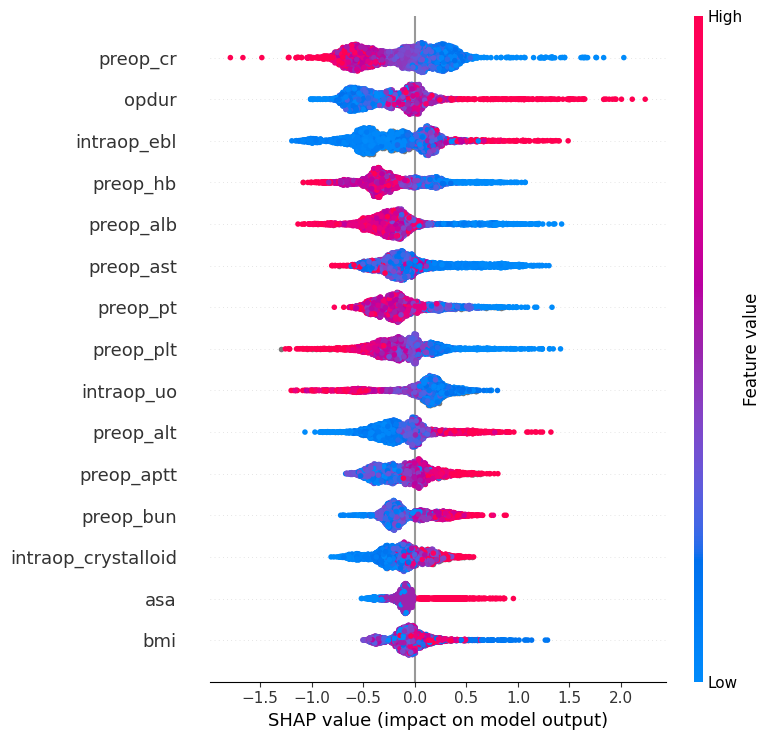

In [43]:
!pip install shap -q
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone

# 1) 교차검증 회차마다: train으로 학습 → test 환자들의 SHAP 계산
shap_vals = np.zeros(X2.shape)
for tr, te in cv.split(X2, y, groups):
    m = clone(xgb).fit(X2.iloc[tr], y.iloc[tr])
    shap_vals[te] = shap.TreeExplainer(m).shap_values(X2.iloc[te])

# 2) 변수 중요도 순위 (환자들의 SHAP 절댓값 평균)
imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=X2.columns).sort_values(ascending=False)
print(imp.head(15).round(3))

# 3) 요약 그림 → 드라이브에 저장
shap.summary_plot(shap_vals, X2, max_display=15, show=False)
plt.tight_layout()
#plt.savefig(f'{BASE}/figures/shap_summary_v3.png', dpi=150)
plt.show()

count    3662.00
mean       99.25
std        15.78
min         9.00
25%        92.00
50%       101.00
75%       109.00
max       159.00
Name: preop_pt, dtype: float64


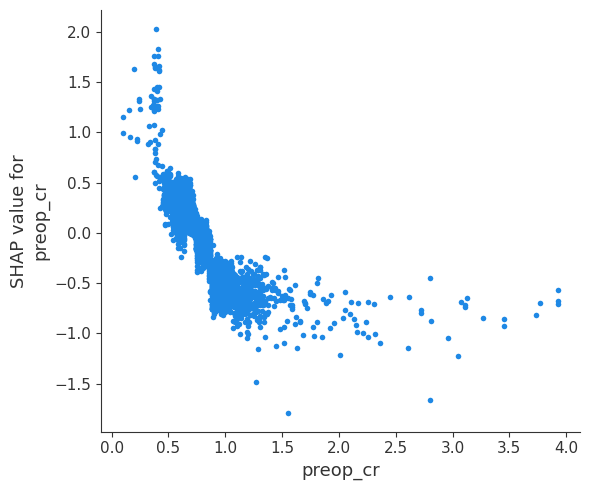

In [44]:
# PT 단위 확인: 값이 100 근처면 % 활성도, 1 근처면 INR, 10~15 근처면 초
print(X2['preop_pt'].describe().round(2))

# 크레아티닌의 효과를 자세히: 값에 따라 SHAP이 어떻게 변하는지
shap.dependence_plot('preop_cr', shap_vals, X2, interaction_index=None, show=False)
plt.tight_layout()
#plt.savefig(f'{BASE}/figures/shap_dependence_cr_v3.png', dpi=150)
plt.show()

# 중요도 순위 저장
#save_df(imp.rename('mean_abs_shap').reset_index().rename(columns={'index': 'variable'}), 'shap_importance_v3')

In [45]:
# 1) 크레아티닌이 낮은 환자: 누구이고, 얼마나 올라서 AKI가 됐나
low = df['preop_cr'] < 0.6
print(f'Cr < 0.6: {low.sum()}명, AKI 비율 {df.loc[low, "aki"].mean():.3f}')
print(df.loc[low & (df['aki'] == 1), 'opname'].value_counts().head(8))
print(df.loc[low & (df['aki'] == 1), ['preop_cr', 'postop_cr_max']].describe().round(2))
print()

# 2) 크레아티닌이 아주 높은 환자: 몇 명이고 AKI는 어떻게 찍혔나
high = df['preop_cr'] >= 4
print(f'Cr >= 4: {high.sum()}명, AKI 비율 {df.loc[high, "aki"].mean():.3f}')
print(df.loc[high, ['opname', 'preop_cr', 'postop_cr_max', 'aki']])

Cr < 0.6: 454명, AKI 비율 0.073
opname
Liver transplantation              12
Exploratory laparotomy              7
Excision                            2
Hemihepatectomy                     1
Lung lobectomy                      1
Small bowel segmental resection     1
Donor hepatectomy                   1
Vascular repair                     1
Name: count, dtype: int64
       preop_cr  postop_cr_max
count     33.00          33.00
mean       0.43           1.61
std        0.14           2.06
min        0.10           0.28
25%        0.38           0.66
50%        0.42           0.99
75%        0.55           1.72
max        0.59          11.54

Cr >= 4: 0명, AKI 비율 nan
Empty DataFrame
Columns: [opname, preop_cr, postop_cr_max, aki]
Index: []


In [46]:
# 1) 동정맥루 수술 환자들의 크레아티닌 분포
fistula = df['opname'].str.contains('arteriovenous fistula', case=False, na=False)
print(f'동정맥루 수술: {fistula.sum()}명')
print(df.loc[fistula, 'preop_cr'].describe().round(2))
print()

# 2) 부갑상선 절제술 환자들의 크레아티닌 (원발성은 투석과 무관할 수 있음)
para = df['opname'].str.contains('parathyroidectomy', case=False, na=False)
print(df.loc[para, ['opname', 'preop_cr', 'aki']])
print()

# 3) 크레아티닌 37.1 환자 확인
print(df.loc[df['postop_cr_max'] > 20, ['caseid', 'opname', 'preop_cr', 'postop_cr_max', 'aki']])

동정맥루 수술: 0명
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: preop_cr, dtype: float64

                          opname  preop_cr  aki
3208  Subtotal parathyroidectomy      1.05    1
3496  Subtotal parathyroidectomy      1.17    0

Empty DataFrame
Columns: [caseid, opname, preop_cr, postop_cr_max, aki]
Index: []


preop_cr               0.350
opdur                  0.340
intraop_ebl            0.340
preop_hb               0.311
preop_alb              0.304
preop_ast              0.283
preop_pt               0.253
preop_plt              0.246
intraop_uo             0.236
preop_alt              0.234
preop_aptt             0.218
preop_bun              0.209
intraop_crystalloid    0.208
asa                    0.158
bmi                    0.148
dtype: float64


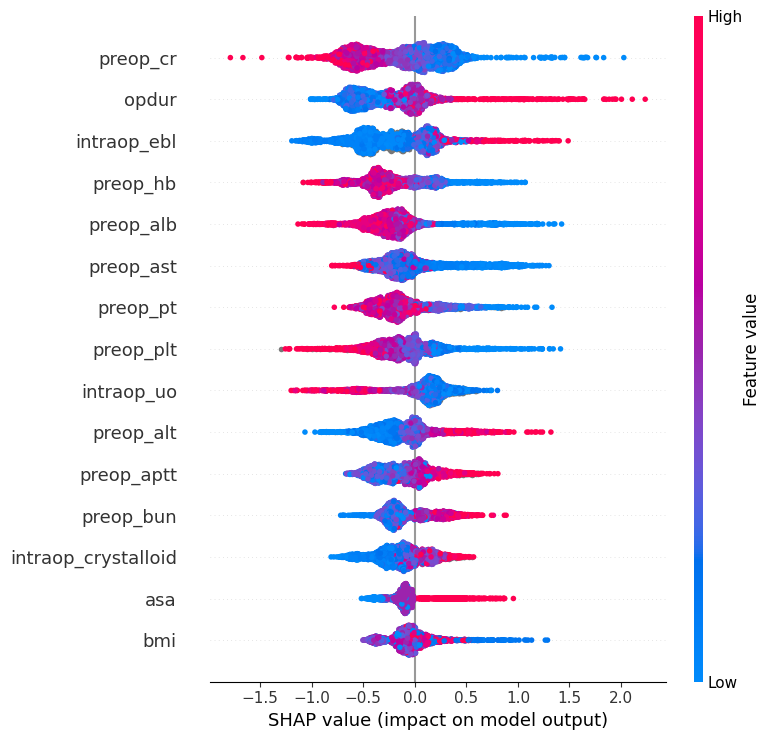

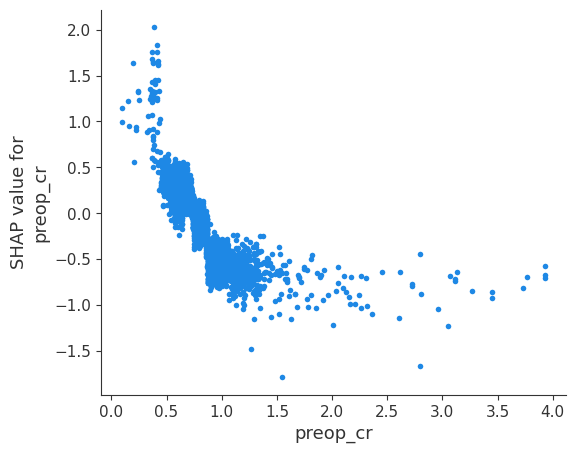

In [47]:
# 1) v3 결과 저장 (CSV)
results = pd.DataFrame({'caseid': df['caseid'].values, 'aki': y_arr, 'is_liver': is_liver,
                        'oof_lr': oof, 'oof_xgb': oof_xgb,
                        'oof_lr2': oof_lr2, 'oof_lr2log': oof_lr2log, 'oof_xgb2': oof_xgb2})
#save_df(results, 'oof_all_v3')
#save_df(coef.rename('coef').reset_index().rename(columns={'index': 'variable'}), 'lr_coef_v3')
#save_df(imp.rename('mean_abs_shap').reset_index().rename(columns={'index': 'variable'}), 'shap_importance_v3')

# 2) v3 그림 저장 (이름에 버전 표시)
shap.summary_plot(shap_vals, X2, max_display=15, show=False)
#plt.tight_layout(); plt.savefig(f'{BASE}/figures/shap_summary_v3.png', dpi=150); plt.close()

shap.dependence_plot('preop_cr', shap_vals, X2, interaction_index=None, show=False)
#plt.tight_layout(); plt.savefig(f'{BASE}/figures/shap_dependence_cr_v3.png', dpi=150); plt.close()

# 3) 비교용 출력
print(imp.head(15).round(3))

[로지스틱 · 수술 전 · KDIGO] AUROC 0.826 ± 0.053 / AUPRC 0.376 ± 0.064
     전체      : AUROC 0.823 / AUPRC 0.367
     간이식 제외: AUROC 0.786 / AUPRC 0.255
     간이식만  : AUROC 0.748 / AUPRC 0.683

[XGBoost · 수술 전 · KDIGO] AUROC 0.809 ± 0.037 / AUPRC 0.347 ± 0.064
     전체      : AUROC 0.807 / AUPRC 0.346
     간이식 제외: AUROC 0.767 / AUPRC 0.222
     간이식만  : AUROC 0.774 / AUPRC 0.728

[로지스틱(로그) · 수술 전+중 · KDIGO] AUROC 0.831 ± 0.054 / AUPRC 0.381 ± 0.091
     전체      : AUROC 0.827 / AUPRC 0.378
     간이식 제외: AUROC 0.791 / AUPRC 0.275
     간이식만  : AUROC 0.771 / AUPRC 0.677

[XGBoost · 수술 전+중 · KDIGO] AUROC 0.820 ± 0.043 / AUPRC 0.371 ± 0.091
     전체      : AUROC 0.817 / AUPRC 0.342
     간이식 제외: AUROC 0.779 / AUPRC 0.238
     간이식만  : AUROC 0.754 / AUPRC 0.681



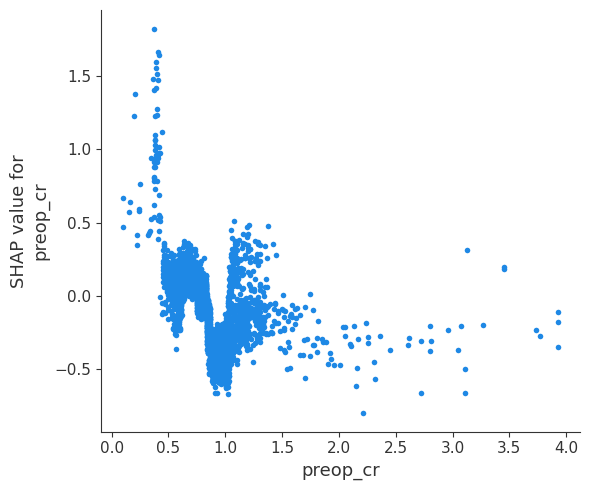

정답 복구 완료: aki


In [48]:
# === 민감도 분석: KDIGO 정의 ===
y_orig = y.copy()
try:
    y = df['aki_kdigo']; y_arr = y.values

    oof_k = {}
    oof_k['lr']   = evaluate(pipe, X,      '로지스틱 · 수술 전 · KDIGO')
    oof_k['xgb']  = evaluate(xgb,  X,      'XGBoost · 수술 전 · KDIGO')
    oof_k['lr2']  = evaluate(pipe, X2_log, '로지스틱(로그) · 수술 전+중 · KDIGO')
    oof_k['xgb2'] = evaluate(xgb,  X2,     'XGBoost · 수술 전+중 · KDIGO')

    shap_k = np.zeros(X2.shape)
    for tr, te in cv.split(X2, y, groups):
        m = clone(xgb).fit(X2.iloc[tr], y.iloc[tr])
        shap_k[te] = shap.TreeExplainer(m).shap_values(X2.iloc[te])
    shap.dependence_plot('preop_cr', shap_k, X2, interaction_index=None, show=False)
    plt.tight_layout()
    plt.savefig(f'{BASE}/figures/shap_dependence_cr_kdigo_v3.png', dpi=150)
    plt.show()
finally:
    y = y_orig; y_arr = y.values   # 에러가 나도 반드시 원래 정답으로 복구
    print('정답 복구 완료:', y.name)

In [49]:
#save_df(pd.DataFrame({'caseid': df['caseid'].values, 'aki_kdigo': df['aki_kdigo'].values,
 #                     'is_liver': is_liver, **{f'oof_{k}': v for k, v in oof_k.items()}}),
  #      'oof_kdigo_v3')

In [50]:
#생체신호
ours = trks[trks['caseid'].isin(df['caseid'])]

for t in ['Solar8000/ART_MBP', 'Solar8000/NIBP_MBP', 'SNUADC/ART']:
    n = ours.loc[ours['tname'] == t, 'caseid'].nunique()
    print(f'{t:22s}: {n}명 ({n / len(df):.1%})')

has_art  = df['caseid'].isin(ours.loc[ours['tname'] == 'Solar8000/ART_MBP',  'caseid'])
has_nibp = df['caseid'].isin(ours.loc[ours['tname'] == 'Solar8000/NIBP_MBP', 'caseid'])
print('\n동맥 라인 있음 vs 없음 AKI 비율:',
      f"{df.loc[has_art, 'aki'].mean():.3f} vs {df.loc[~has_art, 'aki'].mean():.3f}")
print('둘 다 없는 환자:', (~has_art & ~has_nibp).sum(), '명')

Solar8000/ART_MBP     : 2713명 (73.0%)
Solar8000/NIBP_MBP    : 3255명 (87.6%)
SNUADC/ART            : 2665명 (71.7%)

동맥 라인 있음 vs 없음 AKI 비율: 0.042 vs 0.017
둘 다 없는 환자: 5 명


In [51]:
import vitaldb, time

case = int(df.loc[has_art, 'caseid'].iloc[0])
t0 = time.time()
vals = vitaldb.load_case(case, ['Solar8000/ART_MBP', 'Solar8000/NIBP_MBP'], 1)
print(f'다운로드 시간: {time.time() - t0:.1f}초')

art, nibp = vals[:, 0], vals[:, 1]
print('배열 크기:', vals.shape)
print('ART 값 개수:', np.sum(~np.isnan(art)), '/ NIBP 값 개수:', np.sum(~np.isnan(nibp)))
print('ART 예시:', np.round(art[~np.isnan(art)][:10], 1))
print('NIBP 예시:', np.round(nibp[~np.isnan(nibp)][:10], 1))

r = df.loc[df['caseid'] == case, ['anestart', 'aneend']].iloc[0]
print(f"마취 시간: {(r['aneend'] - r['anestart']) / 60:.0f}분 / 기록 길이: {len(vals) / 60:.0f}분")

다운로드 시간: 0.2초
배열 크기: (11543, 2)
ART 값 개수: 5449 / NIBP 값 개수: 347
ART 예시: [-8. -8. -8. -9. -9. -8. -8. -9. -9. -9.]
NIBP 예시: [100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]
마취 시간: 190분 / 기록 길이: 192분


In [52]:
import os, warnings

COLS = ['caseid', 'art_used', 'valid_min', 'min_below65', 'pct_below65',
        'auc65', 'map_min', 'map_mean', 'error']

def bp_features(caseid, start, end):
    out = {'caseid': caseid}
    vals = vitaldb.load_case(caseid, ['Solar8000/ART_MBP', 'Solar8000/NIBP_MBP'], 1)
    if vals is None or len(vals) == 0:
        out['error'] = 'no data'; return out

    s, e = int(max(start, 0)), int(min(end, len(vals)))
    n_min = (e - s) // 60
    if n_min <= 0:
        out['error'] = 'no anesthesia window'; return out
    seg = vals[s:s + n_min * 60].copy()
    seg[(seg < 20) | (seg > 200)] = np.nan               # 인공물 제거

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        art_m = np.nanmedian(seg[:, 0].reshape(n_min, 60), axis=1)       # 1분 중앙값
    art_m = pd.Series(art_m).rolling(3, center=True, min_periods=3).median().values   # ← 새로 추가
    nibp_m = (pd.Series(seg[:, 1]).groupby(np.arange(n_min * 60) // 60).last()
              .ffill(limit=10).values)                                   # 마지막 값, 최대 10분 유지

    art_cov = np.mean(~np.isnan(art_m))
    m = art_m if art_cov >= 0.5 else nibp_m
    m = m[~np.isnan(m)]
    if len(m) == 0:
        out['error'] = 'no valid MAP'; return out

    out.update(art_used=int(art_cov >= 0.5), valid_min=len(m),
               min_below65=int(np.sum(m < 65)), pct_below65=np.mean(m < 65),
               auc65=float(np.sum(np.clip(65 - m, 0, None))),
               map_min=float(m.min()), map_mean=float(m.mean()))
    return out

r = df.loc[df['caseid'] == case].iloc[0]
print(bp_features(case, r['anestart'], r['aneend']))

{'caseid': 1, 'art_used': 1, 'valid_min': 167, 'min_below65': 30, 'pct_below65': np.float64(0.17964071856287425), 'auc65': 135.0, 'map_min': 57.0, 'map_mean': 84.30838323353294}


anestart: -552 / aneend: 10848.0


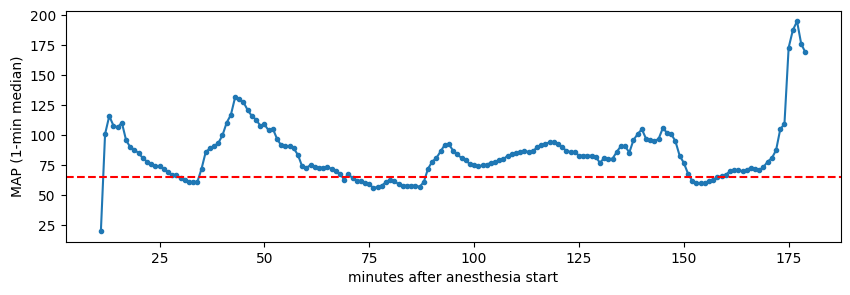

65 미만인 분: [ 11  30  31  32  33  34  69  71  72  73  74  75  76  77  78  79  80  81
  82  83  84  85  86  87  88 152 153 154 155 156 157]
  11분 전후: [ nan  nan  20. 101. 116.]
  30분 전후: [67. 67. 64. 63. 61.]
  31분 전후: [67. 64. 63. 61. 61.]
  32분 전후: [64. 63. 61. 61. 61.]
  33분 전후: [63. 61. 61. 61. 72.]
  34분 전후: [61. 61. 61. 72. 86.]
  69분 전후: [70. 68. 63. 68. 64.]
  71분 전후: [63. 68. 64. 62. 62.]
  72분 전후: [68. 64. 62. 62. 60.]
  73분 전후: [64. 62. 62. 60. 59.]
  74분 전후: [62. 62. 60. 59. 56.]
  75분 전후: [62. 60. 59. 56. 57.]


In [53]:
import matplotlib.pyplot as plt

r = df.loc[df['caseid'] == case].iloc[0]
vals = vitaldb.load_case(case, ['Solar8000/ART_MBP', 'Solar8000/NIBP_MBP'], 1)
v = vals[:, 0]
print('anestart:', r['anestart'], '/ aneend:', r['aneend'])

s = int(max(r['anestart'], 0))                    # 음수면 기록 시작(0)부터
e = int(min(r['aneend'], len(v)))                 # 기록 끝을 넘지 않게
n = (e - s) // 60
seg = v[s:s + n * 60].copy()
seg[(seg < 20) | (seg > 200)] = np.nan
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    art_m = np.nanmedian(seg.reshape(n, 60), axis=1)

plt.figure(figsize=(10, 3))
plt.plot(art_m, marker='.')
plt.axhline(65, color='red', linestyle='--')
plt.xlabel('minutes after anesthesia start'); plt.ylabel('MAP (1-min median)')
plt.show()

low = np.where(art_m < 65)[0]
print('65 미만인 분:', low)
for k in low[:12]:
    print(f'{k:4d}분 전후:', np.round(art_m[max(k - 2, 0):k + 3]))

In [54]:
out_path = f'{BASE}/data/bp_features.csv'
done = set(pd.read_csv(out_path)['caseid']) if os.path.exists(out_path) else set()
todo = df.loc[~df['caseid'].isin(done), ['caseid', 'anestart', 'aneend', 'opstart', 'opend']]
print('이미 완료:', len(done), '명 / 남은 환자:', len(todo), '명')

rows, t0 = [], time.time()
for i, r in enumerate(todo.itertuples(index=False), 1):
    start = r.anestart if pd.notna(r.anestart) else r.opstart
    end   = r.aneend   if pd.notna(r.aneend)   else r.opend
    try:
        rows.append(bp_features(int(r.caseid), start, end))
    except Exception as ex:
        rows.append({'caseid': int(r.caseid), 'error': str(ex)[:100]})

    if i % 200 == 0 or i == len(todo):
        pd.DataFrame(rows).reindex(columns=COLS).to_csv(
            out_path, mode='a', header=not os.path.exists(out_path), index=False)
        rows = []
        print(f'{i}/{len(todo)} 저장 · {(time.time() - t0) / 60:.1f}분 경과')

이미 완료: 3717 명 / 남은 환자: 0 명


In [55]:
bp = pd.read_csv(f'{BASE}/data/bp_features.csv').drop_duplicates('caseid', keep='last')
print('처리된 환자:', len(bp), '/ 에러:', bp['error'].notna().sum())
print(bp['error'].value_counts())
print()
print(bp[['art_used', 'valid_min', 'min_below65', 'pct_below65', 'auc65',
          'map_min', 'map_mean']].describe().T.round(1))

처리된 환자: 3717 / 에러: 1
error
no valid MAP    1
Name: count, dtype: int64

              count   mean    std   min    25%    50%    75%     max
art_used     3716.0    0.7    0.5   0.0    0.0    1.0    1.0     1.0
valid_min    3716.0  202.3  107.2  26.0  122.0  183.0  260.0  1001.0
min_below65  3716.0   17.6   34.6   0.0    1.0    7.0   19.2   480.0
pct_below65  3716.0    0.1    0.1   0.0    0.0    0.0    0.1     1.0
auc65        3716.0  108.2  341.8   0.0    2.0   32.0   99.5  6887.5
map_min      3716.0   57.1   12.7  20.0   52.9   59.0   64.0   103.0
map_mean     3716.0   84.2    9.0  48.9   78.1   83.7   89.7   120.0


In [56]:
# 1) trks상 신호가 둘 다 없던 5명은 실제로 어떻게 처리됐나
neither = df.loc[~has_art & ~has_nibp, 'caseid']
print(bp[bp['caseid'].isin(neither)].to_string())
print()

# 2) 극단값 환자 (AKI 정답은 보지 않음)
ext = bp[(bp['pct_below65'] > 0.8) | (bp['map_min'] < 30) | (bp['map_mean'] < 60)]
print('극단값 환자:', len(ext), '명')
print('map_min < 30:', (bp['map_min'] < 30).sum(), '명 / map_min = 20 근처:', (bp['map_min'] <= 20.5).sum(), '명')
cols = ['caseid', 'art_used', 'valid_min', 'min_below65', 'pct_below65', 'map_min', 'map_mean']
print(ext[cols].sort_values('pct_below65', ascending=False).head(15).to_string())

      caseid  art_used  valid_min  min_below65  pct_below65   auc65  map_min    map_mean         error
1337    2320       NaN        NaN          NaN          NaN     NaN      NaN         NaN  no valid MAP
1767    3026       1.0      350.0        190.0     0.542857  1726.0     23.0   63.752857           NaN
1793    3066       0.0       96.0          0.0     0.000000     0.0     69.0  100.000000           NaN
3052    5269       1.0      102.0         94.0     0.921569  1218.5     41.0   53.225490           NaN
3688    6337       1.0      385.0        316.0     0.820779  3028.0     21.0   57.940260           NaN

극단값 환자: 256 명
map_min < 30: 247 명 / map_min = 20 근처: 19 명
      caseid  art_used  valid_min  min_below65  pct_below65  map_min   map_mean
2743    4748       1.0      176.0        171.0     0.971591     40.5  51.866477
3059    5282       1.0      396.0        381.0     0.962121     29.0  48.914141
2469    4255       1.0      381.0        365.0     0.958005     23.0  51.314961
153

In [60]:
if RUN_HEAVY:
    def art_nibp_diff(caseid, start, end):
        vals = vitaldb.load_case(caseid, ['Solar8000/ART_MBP', 'Solar8000/NIBP_MBP'], 1)
        s, e = int(max(start, 0)), int(min(end, len(vals)))
        seg = vals[s:e].copy()
        seg[(seg < 20) | (seg > 200)] = np.nan
        art, nibp = seg[:, 0], seg[:, 1]
        diffs = []
        for i in np.where(~np.isnan(nibp))[0]:
            a = art[max(i - 30, 0):i + 30]
            if np.sum(~np.isnan(a)) >= 10:
                diffs.append(np.nanmedian(a) - nibp[i])
        return {'caseid': caseid, 'n_pairs': len(diffs),
                'diff_median': np.median(diffs) if diffs else np.nan}

    times = df.set_index('caseid')
    art_ids  = bp.loc[bp['art_used'] == 1, 'caseid']
    flag_ids = ext.loc[ext['art_used'] == 1, 'caseid']
    ctrl_ids = art_ids[~art_ids.isin(flag_ids)].sample(200, random_state=42)

    rows = []
    for grp, ids in [('극단값', flag_ids), ('일반', ctrl_ids)]:
        for c in ids:
            r = times.loc[c]
            st = r['anestart'] if pd.notna(r['anestart']) else r['opstart']
            en = r['aneend']   if pd.notna(r['aneend'])   else r['opend']
            out = art_nibp_diff(int(c), st, en); out['group'] = grp
            rows.append(out)
    cmp = pd.DataFrame(rows)

    print(cmp.groupby('group')['diff_median'].describe().round(1))
    print('\n|차이| > 20 mmHg 비율:')
    print(cmp.assign(big=cmp['diff_median'].abs() > 20).groupby('group')['big'].mean().round(3))
else:
    print('동맥 라인 vs 커프 비교: 건너뜀 (RUN_HEAVY = False). 결과는 교과서 18.12 참고')

동맥 라인 vs 커프 비교: 건너뜀 (RUN_HEAVY = False). 결과는 교과서 18.12 참고


In [61]:
bp_cols = ['art_used', 'valid_min', 'min_below65', 'pct_below65', 'auc65', 'map_min', 'map_mean']
bpi = bp.set_index('caseid')
for c in bp_cols:
    df[c] = df['caseid'].map(bpi[c])

X3 = pd.concat([X2, df[bp_cols]], axis=1)
X3_log = X3.copy()
X3_log[skewed + ['min_below65', 'auc65']] = np.log1p(X3_log[skewed + ['min_below65', 'auc65']])
print('X3 크기:', X3.shape, '/ 혈압 변수 빈 칸:', df['map_mean'].isna().sum(), '명')

X3 크기: (3717, 66) / 혈압 변수 빈 칸: 1 명


In [62]:
oof_lr3   = evaluate(pipe, X3_log, '로지스틱(로그) · 수술 전+중+혈압')
oof_xgb3  = evaluate(xgb,  X3,     'XGBoost · 수술 전+중+혈압')
oof_xgb3n = evaluate(xgb,  X3.drop(columns=['art_used']), 'XGBoost · 혈압 (동맥 라인 유무 제외)')

X3_s = X3.copy()
X3_s.loc[df['caseid'].isin(ext['caseid']).values, bp_cols] = np.nan
oof_xgb3s = evaluate(xgb, X3_s, 'XGBoost · 혈압 (극단값 256명 혈압 변수 제외, 민감도)')

[로지스틱(로그) · 수술 전+중+혈압] AUROC 0.813 ± 0.063 / AUPRC 0.331 ± 0.111
     전체      : AUROC 0.794 / AUPRC 0.298
     간이식 제외: AUROC 0.737 / AUPRC 0.170
     간이식만  : AUROC 0.752 / AUPRC 0.621

[XGBoost · 수술 전+중+혈압] AUROC 0.835 ± 0.054 / AUPRC 0.321 ± 0.123
     전체      : AUROC 0.816 / AUPRC 0.274
     간이식 제외: AUROC 0.767 / AUPRC 0.148
     간이식만  : AUROC 0.758 / AUPRC 0.623

[XGBoost · 혈압 (동맥 라인 유무 제외)] AUROC 0.834 ± 0.061 / AUPRC 0.332 ± 0.129
     전체      : AUROC 0.814 / AUPRC 0.292
     간이식 제외: AUROC 0.764 / AUPRC 0.146
     간이식만  : AUROC 0.772 / AUPRC 0.666

[XGBoost · 혈압 (극단값 256명 혈압 변수 제외, 민감도)] AUROC 0.831 ± 0.047 / AUPRC 0.317 ± 0.128
     전체      : AUROC 0.814 / AUPRC 0.279
     간이식 제외: AUROC 0.765 / AUPRC 0.142
     간이식만  : AUROC 0.722 / AUPRC 0.668



In [63]:
def boot_diff(p_old, p_new, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n):
        b = rng.integers(0, len(y_arr), len(y_arr))
        if y_arr[b].sum() == 0:
            continue
        diffs.append(roc_auc_score(y_arr[b], p_new[b]) - roc_auc_score(y_arr[b], p_old[b]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return f'{np.mean(diffs):+.3f} (95% CI {lo:+.3f} ~ {hi:+.3f})'

print('로지스틱: 수술 전+중 → +혈압', boot_diff(oof_lr2log, oof_lr3))
print('XGBoost : 수술 전+중 → +혈압', boot_diff(oof_xgb2,   oof_xgb3))

로지스틱: 수술 전+중 → +혈압 -0.008 (95% CI -0.013 ~ -0.001)
XGBoost : 수술 전+중 → +혈압 -0.005 (95% CI -0.018 ~ +0.007)


In [65]:
#결과다지기

In [64]:
preds = {'LR 수술전': oof, 'XGB 수술전': oof_xgb,
         'LR 수술전+중': oof_lr2log, 'XGB 수술전+중': oof_xgb2,
         'LR +혈압': oof_lr3, 'XGB +혈압': oof_xgb3}
pairs = [('LR 수술전', 'LR 수술전+중'), ('XGB 수술전', 'XGB 수술전+중'),
         ('LR 수술전', 'XGB 수술전'), ('LR 수술전+중', 'XGB 수술전+중'),
         ('LR 수술전+중', 'LR +혈압'), ('XGB 수술전+중', 'XGB +혈압')]

subj = df['subjectid'].values
uniq = np.unique(subj)
rows_of = pd.Series(np.arange(len(subj))).groupby(subj).apply(np.array)

rng = np.random.default_rng(42)
auc_b = {k: [] for k in preds}; ap_b = {k: [] for k in preds}; dif_b = {p: [] for p in pairs}
for _ in range(1000):
    b = np.concatenate(rows_of.loc[rng.choice(uniq, len(uniq), replace=True)].values)
    yb = y_arr[b]
    auc = {k: roc_auc_score(yb, v[b]) for k, v in preds.items()}
    for k, v in preds.items():
        auc_b[k].append(auc[k]); ap_b[k].append(average_precision_score(yb, v[b]))
    for a, c in pairs:
        dif_b[(a, c)].append(auc[c] - auc[a])

ci = lambda x: np.percentile(x, [2.5, 97.5])
print('모델별 OOF 성능 [95% CI]')
for k, v in preds.items():
    a_lo, a_hi = ci(auc_b[k]); p_lo, p_hi = ci(ap_b[k])
    print(f'  {k:10s} AUROC {roc_auc_score(y_arr, v):.3f} [{a_lo:.3f}–{a_hi:.3f}]'
          f' / AUPRC {average_precision_score(y_arr, v):.3f} [{p_lo:.3f}–{p_hi:.3f}]')
print('\nAUROC 차이 (뒤 − 앞) [95% CI]')
for a, c in pairs:
    lo, hi = ci(dif_b[(a, c)])
    print(f'  {a} → {c}: {np.mean(dif_b[(a, c)]):+.3f} [{lo:+.3f} ~ {hi:+.3f}]')

모델별 OOF 성능 [95% CI]
  LR 수술전     AUROC 0.792 [0.744–0.840] / AUPRC 0.295 [0.194–0.420]
  XGB 수술전    AUROC 0.786 [0.739–0.833] / AUPRC 0.281 [0.183–0.406]
  LR 수술전+중   AUROC 0.802 [0.751–0.850] / AUPRC 0.293 [0.190–0.412]
  XGB 수술전+중  AUROC 0.822 [0.777–0.864] / AUPRC 0.303 [0.210–0.428]
  LR +혈압     AUROC 0.794 [0.742–0.842] / AUPRC 0.298 [0.186–0.421]
  XGB +혈압    AUROC 0.816 [0.769–0.861] / AUPRC 0.274 [0.190–0.391]

AUROC 차이 (뒤 − 앞) [95% CI]
  LR 수술전 → LR 수술전+중: +0.009 [-0.012 ~ +0.029]
  XGB 수술전 → XGB 수술전+중: +0.035 [+0.009 ~ +0.062]
  LR 수술전 → XGB 수술전: -0.007 [-0.038 ~ +0.024]
  LR 수술전+중 → XGB 수술전+중: +0.019 [-0.013 ~ +0.049]
  LR 수술전+중 → LR +혈압: -0.008 [-0.014 ~ -0.002]
  XGB 수술전+중 → XGB +혈압: -0.005 [-0.017 ~ +0.007]


실제 AKI 비율: 0.0355 / 기준 Brier: 0.0343

LR 수술전     Brier 0.0297 / 예측 평균 0.0360 / 보정 기울기 0.72
XGB 수술전    Brier 0.0298 / 예측 평균 0.0292 / 보정 기울기 0.68
LR 수술전+중   Brier 0.0304 / 예측 평균 0.0364 / 보정 기울기 0.62
XGB 수술전+중  Brier 0.0291 / 예측 평균 0.0281 / 보정 기울기 0.68


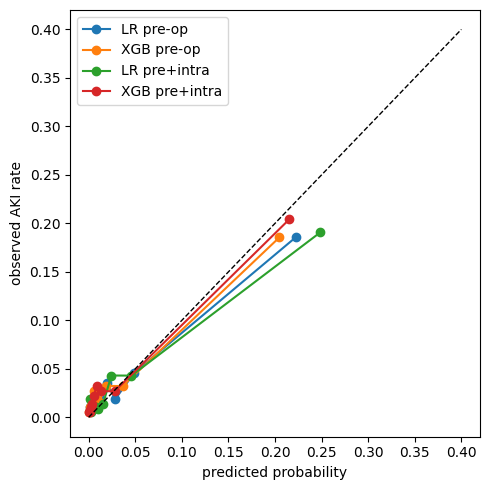

In [66]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import statsmodels.api as sm

main = ['LR 수술전', 'XGB 수술전', 'LR 수술전+중', 'XGB 수술전+중']
lab = {'LR 수술전': 'LR pre-op', 'XGB 수술전': 'XGB pre-op',
       'LR 수술전+중': 'LR pre+intra', 'XGB 수술전+중': 'XGB pre+intra'}
print(f'실제 AKI 비율: {y_arr.mean():.4f} / 기준 Brier: {y_arr.mean() * (1 - y_arr.mean()):.4f}\n')

plt.figure(figsize=(5, 5))
for k in main:
    p = preds[k]
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    slope = sm.Logit(y_arr, sm.add_constant(np.log(pc / (1 - pc)))).fit(disp=0).params[1]
    print(f'{k:10s} Brier {brier_score_loss(y_arr, p):.4f} / 예측 평균 {p.mean():.4f} / 보정 기울기 {slope:.2f}')
    obs, pred = calibration_curve(y_arr, p, n_bins=10, strategy='quantile')
    plt.plot(pred, obs, marker='o', label=lab[k])
plt.plot([0, 0.4], [0, 0.4], 'k--', linewidth=1)
plt.xlabel('predicted probability'); plt.ylabel('observed AKI rate')
plt.legend(); plt.tight_layout()
#plt.savefig(f'{BASE}/figures/calibration_v3.png', dpi=150)
plt.show()

In [67]:
##생체신호 2차

In [68]:
ours = trks[trks['caseid'].isin(df['caseid'])]
cnt = ours.groupby('tname')['caseid'].nunique().sort_values(ascending=False)
print('신호 종류:', len(cnt))
print('\n[펌프 신호]')
print(cnt[cnt.index.str.contains('Orchestra')].head(30).to_string())
print('\n[모니터 신호]')
print(cnt[cnt.index.str.contains('Solar8000')].head(30).to_string())

신호 종류: 192

[펌프 신호]
tname
Orchestra/RFTN20_RATE    3075
Orchestra/RFTN20_VOL     3075
Orchestra/RFTN20_CP      3074
Orchestra/RFTN20_CT      3074
Orchestra/RFTN20_CE      3074
Orchestra/PPF20_CP       2098
Orchestra/PPF20_CT       2098
Orchestra/PPF20_VOL      2098
Orchestra/PPF20_RATE     2098
Orchestra/PPF20_CE       2098
Orchestra/ROC_VOL         224
Orchestra/ROC_RATE        224
Orchestra/PHEN_RATE        94
Orchestra/PHEN_VOL         94
Orchestra/FUT_RATE         76
Orchestra/FUT_VOL          76
Orchestra/PGE1_VOL         73
Orchestra/PGE1_RATE        73
Orchestra/NEPI_VOL         64
Orchestra/NEPI_RATE        64
Orchestra/RFTN50_CE        44
Orchestra/RFTN50_RATE      44
Orchestra/RFTN50_CP        44
Orchestra/RFTN50_CT        44
Orchestra/RFTN50_VOL       44
Orchestra/NTG_RATE         29
Orchestra/NTG_VOL          29
Orchestra/DOPA_VOL         20
Orchestra/DOPA_RATE        20
Orchestra/DEX2_RATE         3

[모니터 신호]
tname
Solar8000/PLETH_SPO2       3716
Solar8000/HR              

In [69]:
import vitaldb

nepi_case = int(ours.loc[ours['tname'] == 'Orchestra/NEPI_RATE', 'caseid'].iloc[0])
tracks = ['Solar8000/HR', 'Orchestra/PHEN_RATE', 'Orchestra/NEPI_RATE', 'Orchestra/DOPA_RATE']
vals = vitaldb.load_case(nepi_case, tracks, 1)
r = df.loc[df['caseid'] == nepi_case].iloc[0]

print('caseid:', nepi_case, '/ 배열 크기:', vals.shape)
print(f"마취: {r['anestart']:.0f}초 ~ {r['aneend']:.0f}초")
for j, t in enumerate(tracks):
    v = vals[:, j]
    idx = np.where(~np.isnan(v))[0]
    if len(idx) == 0:
        print(f'{t:22s}: 값 없음'); continue
    print(f'{t:22s}: 값 {len(idx)}개, 기록 구간 {idx[0]}~{idx[-1]}초, '
          f'고유값 예시 {np.unique(np.round(v[idx], 1))[:8]}')

nepi_idx = np.where(~np.isnan(vals[:, 2]))[0]
print('\nNEPI 기록 간격(초) 예시:', np.diff(nepi_idx)[:15])

caseid: 17 / 배열 크기: (20370, 4)
마취: -180초 ~ 20340초
Solar8000/HR          : 값 9882개, 기록 구간 4~19769초, 고유값 예시 [49. 50. 51. 53. 54. 55. 56. 57.]
Orchestra/PHEN_RATE   : 값 없음
Orchestra/NEPI_RATE   : 값 1993개, 기록 구간 17083~19087초, 고유값 예시 [ 0.   4.8  5.6  6.6  8.   9.6 10.  10.6]
Orchestra/DOPA_RATE   : 값 없음

NEPI 기록 간격(초) 예시: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [70]:
COLS2 = ['caseid', 'vaso_inf', 'vaso_inf_min', 'hr_valid_min', 'hr_mean',
         'min_hr100', 'pct_hr100', 'error']
TRK2 = ['Solar8000/HR', 'Orchestra/PHEN_RATE', 'Orchestra/NEPI_RATE', 'Orchestra/DOPA_RATE']

def hr_vaso_features(caseid, start, end):
    out = {'caseid': caseid}
    vals = vitaldb.load_case(caseid, TRK2, 1)
    if vals is None or len(vals) == 0:
        out['error'] = 'no data'; return out
    s, e = int(max(start, 0)), int(min(end, len(vals)))
    n_min = (e - s) // 60
    if n_min <= 0:
        out['error'] = 'no anesthesia window'; return out
    seg = vals[s:s + n_min * 60].copy()

    # H1: 승압제 지속 주입 (세 약 중 하나라도 속도 > 0인 분)
    rates = np.nan_to_num(seg[:, 1:4], nan=0).reshape(n_min, 60, 3)
    on_min = (rates > 0).any(axis=(1, 2))
    out['vaso_inf'] = int(on_min.any())
    out['vaso_inf_min'] = int(on_min.sum())

    # H2: 심박수 (혈압과 같은 정리 방식)
    hr = seg[:, 0]
    hr[(hr < 30) | (hr > 250)] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        hr_m = np.nanmedian(hr.reshape(n_min, 60), axis=1)
    hr_m = pd.Series(hr_m).rolling(3, center=True, min_periods=3).median().values
    hr_m = hr_m[~np.isnan(hr_m)]
    if len(hr_m) == 0:
        out['error'] = 'no valid HR'; return out
    out.update(hr_valid_min=len(hr_m), hr_mean=float(hr_m.mean()),
               min_hr100=int((hr_m > 100).sum()), pct_hr100=float((hr_m > 100).mean()))
    return out

print(hr_vaso_features(nepi_case, r['anestart'], r['aneend']))

{'caseid': 17, 'vaso_inf': 1, 'vaso_inf_min': 35, 'hr_valid_min': 328, 'hr_mean': 72.1844512195122, 'min_hr100': 0, 'pct_hr100': 0.0}


In [71]:
out_path2 = f'{BASE}/data/hr_vaso_features.csv'
done2 = set(pd.read_csv(out_path2)['caseid']) if os.path.exists(out_path2) else set()
todo2 = df.loc[~df['caseid'].isin(done2), ['caseid', 'anestart', 'aneend', 'opstart', 'opend']]
print('이미 완료:', len(done2), '명 / 남은 환자:', len(todo2), '명')

rows, t0 = [], time.time()
for i, r2 in enumerate(todo2.itertuples(index=False), 1):
    st = r2.anestart if pd.notna(r2.anestart) else r2.opstart
    en = r2.aneend   if pd.notna(r2.aneend)   else r2.opend
    try:
        rows.append(hr_vaso_features(int(r2.caseid), st, en))
    except Exception as ex:
        rows.append({'caseid': int(r2.caseid), 'error': str(ex)[:100]})

    if i % 200 == 0 or i == len(todo2):
        pd.DataFrame(rows).reindex(columns=COLS2).to_csv(
            out_path2, mode='a', header=not os.path.exists(out_path2), index=False)
        rows = []
        print(f'{i}/{len(todo2)} 저장 · {(time.time() - t0) / 60:.1f}분 경과')

이미 완료: 3717 명 / 남은 환자: 0 명


In [72]:
hv = pd.read_csv(f'{BASE}/data/hr_vaso_features.csv').drop_duplicates('caseid', keep='last')
print('처리된 환자:', len(hv), '/ 에러:', hv['error'].notna().sum())
print(hv['error'].value_counts())
print()

# H1: 승압제 지속 주입
print('승압제 지속 주입 환자:', int(hv['vaso_inf'].sum()), '명',
      f"({hv['vaso_inf'].mean():.1%})")
print(hv.loc[hv['vaso_inf'] == 1, 'vaso_inf_min'].describe().round(1))
print()

# trks 목록과 비교 (세 약 중 하나라도 있는 환자)
vaso_trk = ours.loc[ours['tname'].isin(['Orchestra/PHEN_RATE', 'Orchestra/NEPI_RATE',
                                        'Orchestra/DOPA_RATE']), 'caseid'].unique()
print('trks상 승압제 신호 보유:', len(vaso_trk), '명 / 그중 실제 주입(vaso_inf=1):',
      int(hv.loc[hv['caseid'].isin(vaso_trk), 'vaso_inf'].sum()), '명')
print('trks에 없는데 주입으로 잡힌 환자:',
      int(hv.loc[~hv['caseid'].isin(vaso_trk), 'vaso_inf'].sum()), '명')
print()

# H2: 심박수
print(hv[['hr_valid_min', 'hr_mean', 'min_hr100', 'pct_hr100']].describe().T.round(1))

처리된 환자: 3717 / 에러: 1
error
<urlopen error [Errno 104] Connection reset by peer>    1
Name: count, dtype: int64

승압제 지속 주입 환자: 168 명 (4.5%)
count    168.0
mean     150.8
std      109.9
min       15.0
25%       79.8
50%      122.5
75%      193.5
max      622.0
Name: vaso_inf_min, dtype: float64

trks상 승압제 신호 보유: 168 명 / 그중 실제 주입(vaso_inf=1): 168 명
trks에 없는데 주입으로 잡힌 환자: 0 명

               count   mean    std   min    25%    50%    75%     max
hr_valid_min  3716.0  207.3  110.4  22.0  123.0  189.0  267.2  1015.0
hr_mean       3716.0   72.2   12.7  44.9   63.2   70.5   79.1   139.8
min_hr100     3716.0   10.7   40.2   0.0    0.0    0.0    4.0   862.0
pct_hr100     3716.0    0.0    0.1   0.0    0.0    0.0    0.0     1.0


In [73]:
#drive.flush_and_unmount()